# B-physics emulator: validation in the low-$\Delta\chi^2$ region

This notebook validates the **statistical fidelity of the XGBoost surrogate in the
low-$\Delta\chi^2$ region** that sets the confidence contours of the flavour
(Scenario III) analysis, as reported in Section 3.1.2 of the paper
(*Universe* **12** (2026) 238). It reuses the trained model
(`outputs/xgboost_scIII.json`) and the dataset of the main notebook; nothing is retrained.

Run it with the paper environment (`.venv-paper`, which has both `xgboost` and
`SMEFT19`). Sections and the paper items they produce:

1. **Signed residual distributions** ($\delta\chi^2=\chi^2_{\rm surr}-\chi^2_{\rm exact}$, split by sign) — Fig. 1b (`ref_bphys_residuals.pdf`).
2. **Emulator error in the low-$\Delta\chi^2$ region** (MAE/RMSE binned by exact $\Delta\chi^2$) — Table 2.
3. **Exact vs surrogate confidence contours** (displacement, area, best-fit shift) — Fig. 2 (`ref_bphys_maps_contours.pdf`).
4. **Closure test**: exact `SMEFT19` likelihood at points drawn from the surrogate posterior — Fig. 1c (`ref_bphys_closure.pdf`).

All labels used in Sections 1-3 are exact `SMEFT19` values already cached in the
dataset, so those sections cost nothing; only Section 4 performs new exact evaluations
(cached in `outputs/ref_bphys_closure_cache.npz`).


In [1]:
import os
# single-threaded BLAS: the exact-likelihood closure test (Section 4) forks many
# workers, and multi-threaded numpy/flavio inside each would oversubscribe the CPU.
for _v in ('OMP_NUM_THREADS', 'MKL_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'NUMEXPR_NUM_THREADS'):
    os.environ.setdefault(_v, '1')
import sys, warnings, time, multiprocessing
warnings.filterwarnings('ignore')
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from scipy.stats import pearsonr
from xgboost import XGBRegressor
import yaml

# ---- paths / config (mirror the main notebook) -------------------------------
ROOT     = Path('..')
DATA_DIR = ROOT / 'data'
OUT_DIR  = ROOT / 'outputs'
DATASET_FILE = DATA_DIR / 'combined_rotBIII_2025.dat'
BESTFIT_FILE = DATA_DIR / 'rotBIII_2025.yaml'
MODEL_FILE   = OUT_DIR  / 'xgboost_scIII.json'
FIGS_DIR     = OUT_DIR  / 'figures'; FIGS_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT / 'scripts'))   # for setup_likelihood (Section 4)

C1_RANGE, C3_RANGE, BQ_RANGE = (-0.30, 0.0), (-0.30, 0.0), (0.0, 3.20)
LH_MIN, SEED, N_DOF, GRID_SIZE = -50.0, 42, 3, 40
N_WORKERS = max(1, multiprocessing.cpu_count() - 1)
plt.rcParams.update({'font.size': 13, 'axes.labelsize': 14, 'figure.dpi': 110})

# ---- data + identical 84/16 split as the main notebook -----------------------
df_raw = pd.read_csv(DATASET_FILE, names=['C1', 'C3', 'bq', 'likelihood'])
df = df_raw[df_raw['likelihood'] > LH_MIN].reset_index(drop=True)
X, y = df[['C1', 'C3', 'bq']], df['likelihood']
Xtr, Xva, ytr, yva = train_test_split(X, y, test_size=0.16, random_state=SEED)

# ---- model + reference points ------------------------------------------------
model = XGBRegressor(); model.load_model(str(MODEL_FILE))

def predL(C1, C3, bq):
    return float(model.predict(pd.DataFrame([{'C1': C1, 'C3': C3, 'bq': bq}]))[0])

with open(BESTFIT_FILE) as f:
    _ell = yaml.safe_load(f)
bf_arr   = np.array(_ell['bf'])
_V, _d   = np.array(_ell['v']), np.array([_ell['d'][i][i] for i in range(3)])
Sigma_bf = _V.T @ np.diag(1.0 / _d) @ _V           # fit covariance (for the MCMC proposal)

logL_SM       = predL(0.0, 0.0, 0.0)               # emulator at the SM point
logL_bf_exact = float(df['likelihood'].max())      # exact global max (true best fit)
logL_bf_model = float(model.predict(X).max())      # emulator max over the dataset points

print(f'validation points : {len(Xva)}   (of {len(df)} valid, {len(df_raw)} total)')
print(f'emulator logL(SM) : {logL_SM:.3f}')
print(f'exact best-fit logL: {logL_bf_exact:.3f}   emulator best-fit logL: {logL_bf_model:.3f}')

validation points : 2887   (of 18041 valid, 25896 total)
emulator logL(SM) : -1.959
exact best-fit logL: 22.364   emulator best-fit logL: 22.585


## 1. Signed residual distributions

A single unsigned metric (MAE) cannot tell whether the surrogate tends to over- or
under-estimate $\chi^2$, which is what decides whether emulated contours over- or
under-cover. We therefore report the **positive and negative** residuals separately,
with
$\delta\chi^2=\chi^2_{\rm surr}-\chi^2_{\rm exact}=-2\,(\log\mathcal{L}_{\rm surr}-\log\mathcal{L}_{\rm exact})$
on the held-out validation set (whose labels are exact `SMEFT19` values):

* $\delta\chi^2>0$: the surrogate **over-estimates** $\chi^2$ (upward bias -> would spuriously exclude allowed regions).
* $\delta\chi^2<0$: the surrogate **under-estimates** $\chi^2$ (would spuriously allow regions).


n_val = 2887   (in units of chi2)
over-estimates  (dchi2>0):  1482  (51.3%)  mean +1.85  worst +30.6
under-estimates (dchi2<0):  1405  (48.7%)  mean -1.86  worst -26.9
overall bias (mean dchi2): +0.044   median +0.039
MAE = 1.854   RMSE = 3.640   (chi2 units)
Pearson r on Delta chi2_SM (Fig 7a scale) = 0.9921


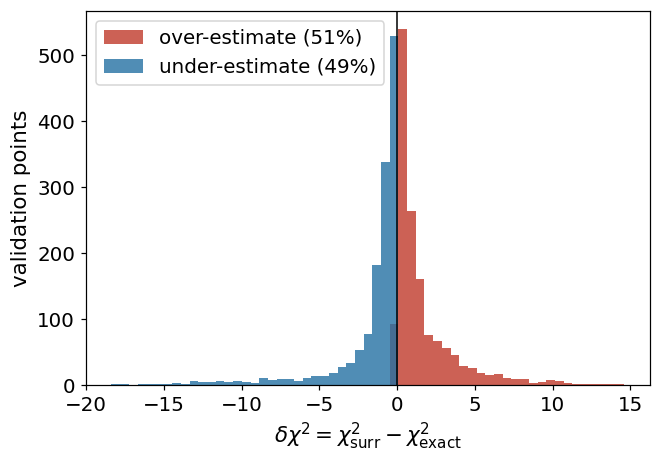

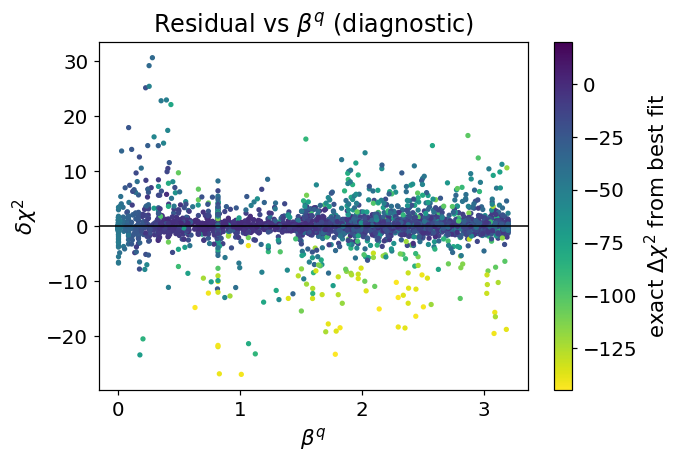

In [2]:
y_pred = model.predict(Xva)
resid_logL  = y_pred - yva.values                 # surrogate - exact, in logL
delta_chi2  = -2.0 * resid_logL                    # chi2_surr - chi2_exact
# on the Delta chi2_SM scale of Fig 7a (predicted - actual): 2*(pred - exact)
resid_dSM   = 2.0 * resid_logL

pos, neg = delta_chi2[delta_chi2 > 0], delta_chi2[delta_chi2 < 0]
rmse = float(np.sqrt(np.mean(delta_chi2**2)))
mae  = float(np.mean(np.abs(delta_chi2)))
r_dSM, _ = pearsonr(2*(yva.values - logL_SM), 2*(y_pred - logL_SM))

print(f'n_val = {len(delta_chi2)}   (in units of chi2)')
print(f'over-estimates  (dchi2>0): {len(pos):5d}  ({100*len(pos)/len(delta_chi2):.1f}%)  mean +{pos.mean():.2f}  worst +{pos.max():.1f}')
print(f'under-estimates (dchi2<0): {len(neg):5d}  ({100*len(neg)/len(delta_chi2):.1f}%)  mean {neg.mean():.2f}  worst {neg.min():.1f}')
print(f'overall bias (mean dchi2): {delta_chi2.mean():+.3f}   median {np.median(delta_chi2):+.3f}')
print(f'MAE = {mae:.3f}   RMSE = {rmse:.3f}   (chi2 units)')
print(f'Pearson r on Delta chi2_SM (Fig 7a scale) = {r_dSM:.4f}')

# Figure for the paper: signed-residual histogram
fig, ax = plt.subplots(figsize=(6.2, 4.4))
b = np.linspace(np.percentile(delta_chi2, 0.5), np.percentile(delta_chi2, 99.5), 60)
ax.hist(pos, bins=b, color='#c0392b', alpha=0.8, label=f'over-estimate ({100*len(pos)/len(delta_chi2):.0f}%)')
ax.hist(neg, bins=b, color='#2471a3', alpha=0.8, label=f'under-estimate ({100*len(neg)/len(delta_chi2):.0f}%)')
ax.axvline(0, color='k', lw=1)
ax.set_xlabel(r'$\delta\chi^2=\chi^2_{\rm surr}-\chi^2_{\rm exact}$')
ax.set_ylabel('validation points'); ax.legend()
fig.tight_layout(); plt.savefig(FIGS_DIR / 'ref_bphys_residuals.pdf', bbox_inches='tight'); plt.show()

# Separate diagnostic (repo only, downloadable on its own): residual vs bq
fig, ax = plt.subplots(figsize=(6.4, 4.4))
sc = ax.scatter(Xva['bq'], delta_chi2, c=2*(yva.values-logL_bf_exact), s=6, cmap='viridis_r', vmax=20)
ax.axhline(0, color='k', lw=1); ax.set_xlabel(r'$\beta^q$'); ax.set_ylabel(r'$\delta\chi^2$')
plt.colorbar(sc, ax=ax, label=r'exact $\Delta\chi^2$ from best fit')
ax.set_title(r'Residual vs $\beta^q$ (diagnostic)')
fig.tight_layout(); plt.savefig(FIGS_DIR / 'ref_bphys_residual_vs_bq.pdf', bbox_inches='tight'); plt.show()

## 2. Emulator error in the low-$\Delta\chi^2$ region (Table 2)

A single global metric (r, MAE over the whole domain) can hide whether the errors
sit in the statistically relevant band. Here we bin the validation residuals by the
**exact** $\Delta\chi^2$ from the best fit and report the error inside the
$1\sigma$/$2\sigma$ bands (2D thresholds $\Delta\chi^2=2.30,\,6.18$; the 3-parameter
volume threshold $\Delta\chi^2\!\le\!8.03$ for $2\sigma$ is also shown).


In [3]:
dchi2_exact = 2.0 * (logL_bf_exact - yva.values)     # exact Delta chi2 from the best fit
edges = [('all', np.inf), ('<=8.03 (2s, 3 dof)', 8.03), ('<=6.18 (2s, 2D)', 6.18),
         ('<=2.30 (1s, 2D)', 2.30), ('<=1.00 (1s, 1D)', 1.00)]
print(f'{"region":24s} {"n":>6s} {"MAE":>8s} {"RMSE":>8s} {"bias":>8s}   (chi2 units)')
for name, thr in edges:
    m = dchi2_exact <= thr
    if m.sum() == 0:
        print(f'{name:24s} {0:6d}      --       --       --'); continue
    dd = delta_chi2[m]
    print(f'{name:24s} {m.sum():6d} {np.mean(np.abs(dd)):8.3f} {np.sqrt(np.mean(dd**2)):8.3f} {dd.mean():+8.3f}')

region                        n      MAE     RMSE     bias   (chi2 units)
all                        2887    1.854    3.640   +0.044
<=8.03 (2s, 3 dof)          723    0.662    0.936   +0.085
<=6.18 (2s, 2D)             533    0.597    0.849   +0.125
<=2.30 (1s, 2D)             208    0.498    0.765   +0.347
<=1.00 (1s, 1D)              99    0.464    0.589   +0.413


## 3. Exact vs surrogate confidence contours (Fig. 2)

The three $40\times40$ plane grids stored in the dataset carry exact `SMEFT19`
values; we predict the emulator on the same points (free) and compare the
$1\sigma$/$2\sigma$ contours ($\Delta\chi^2\le2.30,\,6.18$, each slice
referenced to its own maximum), quantifying the **2$\sigma$ area ratio** and the
**best-fit displacement** (in units of the local $\sigma$).


plane C1-C3: 2s area ratio (emu/exact) = 1.292   best-fit shift = (-0.023,-0.015) = (-7.7%,-5.1% of range)
plane C1-bq: 2s area ratio (emu/exact) = 1.192   best-fit shift = (+0.000,-0.082) = (+0.0%,-2.6% of range)
plane C3-bq: 2s area ratio (emu/exact) = 1.290   best-fit shift = (+0.000,+0.082) = (+0.0%,+2.6% of range)


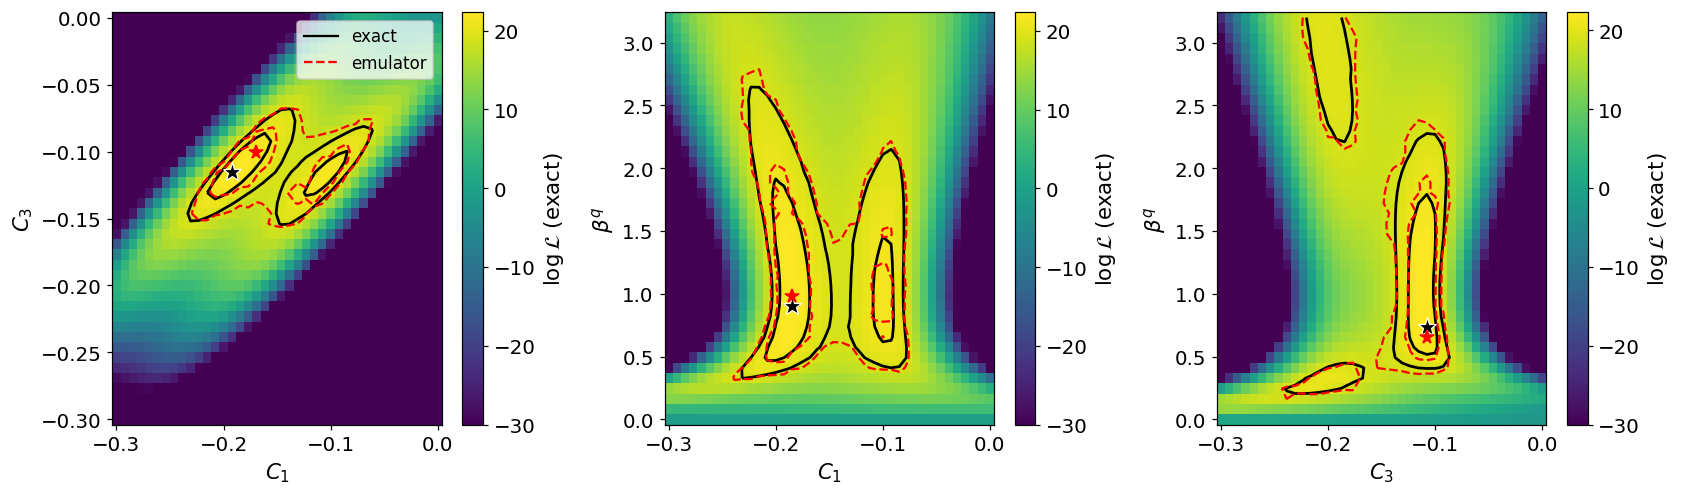

In [4]:
_g2, _base = GRID_SIZE**2, len(df_raw) - 3*GRID_SIZE**2
PLANES = [('C1', 'C3', _base,          _base+_g2,   r'$C_1$', r'$C_3$'),
          ('C1', 'bq', _base+_g2,      _base+2*_g2, r'$C_1$', r'$\beta^q$'),
          ('C3', 'bq', _base+2*_g2,    _base+3*_g2, r'$C_3$', r'$\beta^q$')]
LVL = {'1s': 2.30, '2s': 6.18}

LH_CLIP = -30.0
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.7))
for ax, (cx, cy, s0, s1, xl, yl) in zip(axes, PLANES):
    g = df_raw.iloc[s0:s1]
    gx = g[cx].values.reshape(GRID_SIZE, GRID_SIZE)
    gy = g[cy].values.reshape(GRID_SIZE, GRID_SIZE)
    Le = g['likelihood'].values.reshape(GRID_SIZE, GRID_SIZE)                  # exact logL
    Lm = model.predict(g[['C1', 'C3', 'bq']]).reshape(GRID_SIZE, GRID_SIZE)    # emulator logL
    De = 2.0 * (Le.max() - Le); Dm = 2.0 * (Lm.max() - Lm)                     # Delta chi2 per slice
    cell = abs(gx[1, 0]-gx[0, 0]) * abs(gy[0, 1]-gy[0, 0])
    area_e = (De <= LVL['2s']).sum() * cell; area_m = (Dm <= LVL['2s']).sum() * cell
    be = np.unravel_index(np.argmin(De), De.shape); bm = np.unravel_index(np.argmin(Dm), Dm.shape)
    dx = gx[be] - gx[bm]; dy = gy[be] - gy[bm]
    sx = (gx.max()-gx.min()); sy = (gy.max()-gy.min())
    print(f'plane {cx}-{cy}: 2s area ratio (emu/exact) = {area_m/area_e:.3f}   '
          f'best-fit shift = ({dx:+.3f},{dy:+.3f}) = ({100*dx/sx:+.1f}%,{100*dy/sy:+.1f}% of range)')
    # exact log-likelihood map (background, shows the curved bq ridge) + 1s/2s contours overlaid
    im = ax.pcolormesh(gx, gy, np.clip(Le, LH_CLIP, None), cmap='viridis', shading='auto')
    ax.contour(gx, gy, De, levels=[LVL['1s'], LVL['2s']], colors='k',   linewidths=1.8)
    ax.contour(gx, gy, Dm, levels=[LVL['1s'], LVL['2s']], colors='red', linewidths=1.5, linestyles='--')
    ax.plot(gx[be], gy[be], marker='*', color='k',   ms=13, mec='w', mew=0.8)
    ax.plot(gx[bm], gy[bm], marker='*', color='red', ms=9)
    plt.colorbar(im, ax=ax, label=r'$\log\mathcal{L}$ (exact)')
    ax.set_xlabel(xl); ax.set_ylabel(yl)
axes[0].plot([], [], 'k-', label='exact'); axes[0].plot([], [], 'r--', label='emulator')
axes[0].legend(loc='upper right', fontsize=11, framealpha=0.75)
fig.tight_layout(); plt.savefig(FIGS_DIR / 'ref_bphys_maps_contours.pdf', bbox_inches='tight'); plt.show()

## 4. Closure test: exact likelihood at points drawn from the surrogate posterior (Fig. 1c)

We sample the emulated posterior with the same Metropolis MCMC as the main
notebook, draw a representative subset, and **re-evaluate the exact `SMEFT19`
log-likelihood** at those points (parallel fork `Pool`, `.venv-paper`). This
directly tests whether the surrogate reproduces the exact likelihood over the
region the posterior actually occupies, including near the confidence boundary,
and yields the $\Delta\chi^2$ closure distribution compared with the $\chi^2_3$
(Wilks) reference.


In [5]:
# --- emulator MCMC (same settings as the main notebook Fig 7b) ---------------
N_BURN, N_KEEP = 3000, 15000
rng = np.random.default_rng(SEED + 77)
chol = np.linalg.cholesky(Sigma_bf)
lo, hi = np.array([C1_RANGE[0], C3_RANGE[0], BQ_RANGE[0]]), np.array([C1_RANGE[1], C3_RANGE[1], BQ_RANGE[1]])
x = np.array(bf_arr, float); L = predL(*x)
for i in range(N_BURN):
    p = np.clip(x + chol @ rng.standard_normal(3), lo, hi); Lp = predL(*p)
    if np.log(rng.uniform()) < Lp - L: x, L = p, Lp
keptX = np.empty((N_KEEP, 3)); keptL = np.empty(N_KEEP)
for i in range(N_KEEP):
    p = np.clip(x + chol @ rng.standard_normal(3), lo, hi); Lp = predL(*p)
    if np.log(rng.uniform()) < Lp - L: x, L = p, Lp
    keptX[i], keptL[i] = x, L
print(f'emulator posterior: {N_KEEP} samples,  mean Delta chi2 = {np.mean(2*(logL_bf_model-keptL)):.2f}')

# --- draw a representative subset for the exact re-evaluation -----------------
N_CLOSURE = 1000
idx = rng.choice(N_KEEP, size=N_CLOSURE, replace=False)
subX, subL_emu = keptX[idx], keptL[idx]

emulator posterior: 15000 samples,  mean Delta chi2 = 4.07


In [6]:
# --- exact SMEFT19 log-likelihood at the drawn points (cached; parallel) ------
# The exact evaluations are the only expensive step (~12 min for 1000 points), so
# they are cached to disk keyed on N_CLOSURE. Delete the .npz to force a recompute.
CLOSURE_CACHE = OUT_DIR / 'ref_bphys_closure_cache.npz'

if CLOSURE_CACHE.exists() and int(np.load(CLOSURE_CACHE)['n']) == N_CLOSURE:
    subL_exact = np.load(CLOSURE_CACHE)['subL_exact']
    print(f'loaded {N_CLOSURE} cached exact evaluations from {CLOSURE_CACHE.name}')
else:
    from setup_likelihood import setup_global_likelihood
    import SMEFT19
    setup_global_likelihood(verbose=False)       # warm the likelihood in the parent (fork inherits it)
    _sc = SMEFT19.scenarios.massrotation

    def _exact_worker(row):
        import warnings as _w; _w.simplefilter('ignore')
        c1, c3, bq = row
        try:
            return max(float(SMEFT19.likelihood_global([c1, c3, 0.0, 0.0, 0.0, bq], _sc)), -200.0)
        except Exception:
            return np.nan

    try:
        from threadpoolctl import threadpool_limits
    except Exception:                            # no-op fallback
        from contextlib import contextmanager
        @contextmanager
        def threadpool_limits(*a, **k):
            yield

    t0 = time.time()
    ctx = multiprocessing.get_context('fork')
    with threadpool_limits(limits=1), ctx.Pool(N_WORKERS) as pool:
        subL_exact = np.array(list(pool.imap(_exact_worker, subX, chunksize=8)))
    np.savez(CLOSURE_CACHE, subL_exact=subL_exact, n=N_CLOSURE)
    print(f'exact evaluations: {np.isfinite(subL_exact).sum()}/{N_CLOSURE} in {time.time()-t0:.0f}s '
          f'on {N_WORKERS} workers (cached to {CLOSURE_CACHE.name})')

ok = np.isfinite(subL_exact)

loaded 1000 cached exact evaluations from ref_bphys_closure_cache.npz


posterior closure (1000 pts):
  MAE(logL) = 0.577   RMSE(chi2) = 1.727
  over-estimate chi2: 47.5%   bias(chi2) = -0.340
  within 6.18 of best fit ( 846 pts): RMSE(chi2) = 1.415
  within  2.3 of best fit ( 288 pts): RMSE(chi2) = 1.037


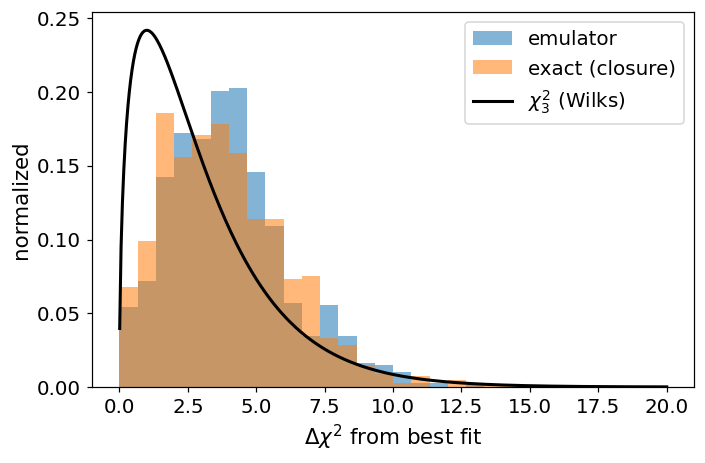

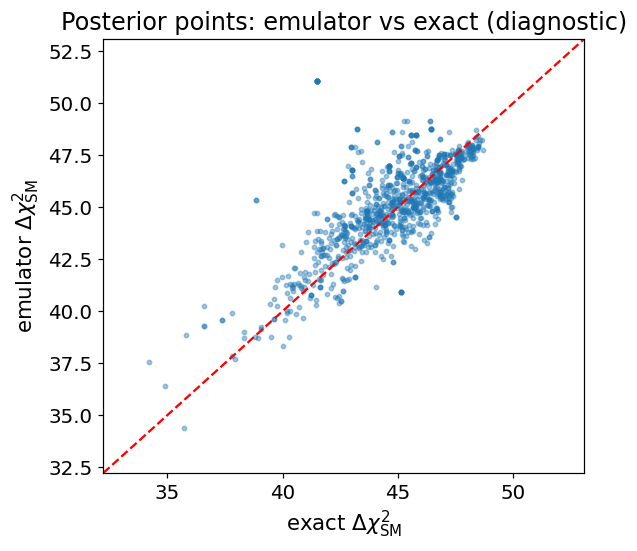

In [7]:
# --- compare emulator vs exact at the posterior points ------------------------
e_emu, e_exa = subL_emu[ok], subL_exact[ok]
dchi2_res = -2.0 * (e_emu - e_exa)                          # chi2_surr - chi2_exact
print(f'posterior closure ({ok.sum()} pts):')
print(f'  MAE(logL) = {np.mean(np.abs(e_emu-e_exa)):.3f}   RMSE(chi2) = {np.sqrt(np.mean(dchi2_res**2)):.3f}')
print(f'  over-estimate chi2: {100*np.mean(dchi2_res>0):.1f}%   bias(chi2) = {dchi2_res.mean():+.3f}')

# error restricted to the low-Delta chi2 part of the posterior
dchi2_post_exact = 2.0 * (logL_bf_exact - e_exa)
for thr in (6.18, 2.30):
    m = dchi2_post_exact <= thr
    if m.sum():
        print(f'  within {thr:>4} of best fit ({m.sum():4d} pts): RMSE(chi2) = {np.sqrt(np.mean(dchi2_res[m]**2)):.3f}')

from scipy.stats import chi2 as _chi2d
# Figure for the paper: closure histogram (emulator vs exact vs chi2_3)
fig, ax = plt.subplots(figsize=(6.6, 4.4))
b = np.linspace(0, 20, 31)
ax.hist(np.maximum(0, 2*(logL_bf_model - e_emu)), bins=b, density=True, alpha=0.55, color='C0', label='emulator')
ax.hist(np.maximum(0, 2*(logL_bf_exact - e_exa)), bins=b, density=True, alpha=0.55, color='C1', label='exact (closure)')
_xs = np.linspace(0.01, 20, 400)
ax.plot(_xs, _chi2d.pdf(_xs, df=N_DOF), 'k-', lw=2.0, label=r'$\chi^2_{3}$ (Wilks)')
ax.set_xlabel(r'$\Delta\chi^2$ from best fit'); ax.set_ylabel('normalized'); ax.legend()
fig.tight_layout(); plt.savefig(FIGS_DIR / 'ref_bphys_closure.pdf', bbox_inches='tight'); plt.show()

# Separate diagnostic (repo only): per-point emulator vs exact scatter on the posterior
fig, ax = plt.subplots(figsize=(5.6, 5.2))
ax.scatter(2*(e_exa-logL_SM), 2*(e_emu-logL_SM), s=8, alpha=0.4)
lim = [2*(min(e_exa.min(), e_emu.min())-logL_SM)-2, 2*(max(e_exa.max(), e_emu.max())-logL_SM)+2]
ax.plot(lim, lim, 'r--'); ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel(r'exact $\Delta\chi^2_{\rm SM}$'); ax.set_ylabel(r'emulator $\Delta\chi^2_{\rm SM}$')
ax.set_title('Posterior points: emulator vs exact (diagnostic)')
fig.tight_layout(); plt.savefig(FIGS_DIR / 'ref_bphys_closure_scatter.pdf', bbox_inches='tight'); plt.show()